# LSST Y1 × DESI DR1: Fisher forecasts on the Δz = 0.2 binning

This notebook forecasts the cosmological constraints of three probes, each through its
own cobaya model, so every derivative differentiates exactly the data vector its
likelihood scores:

1. **DESI clustering alone (1x2pt)**: the angular band powers $C_\ell^{gg}$ of the DESI
   DR1 samples in ten fixed-width bins of $\Delta z = 0.2$, autos and the 13 measured
   cross pairs ([EXAMPLE_EVALUATE4.yaml](EXAMPLE_EVALUATE4.yaml));
2. **LSST Y1 3x2pt**: cosmic shear, galaxy-galaxy lensing and clustering of the LSST Y1
   lens and source samples (the lsst_y1 project's n(z)), in band powers on the same 53
   bands ([EXAMPLE_EVALUATE5.yaml](EXAMPLE_EVALUATE5.yaml));
3. **6x2pt**: the two together, as independent data sets.

It then uses the same derivatives for **Fisher biases**: how far the best-fit cosmology
moves when the model fitted to the data makes a different projection choice than the
one that generated them (the FKEM split against the low-rank SVD engine, Limber
against non-Limber).

| Choice | Value |
| --- | --- |
| Cosmology | $w_0w_a$CDM: $10^9A_s$, $n_s$, $H_0$, $\Omega_b$, $\Omega_m$, $w_0$, $w_a$ varied; $\sum m_\nu = 0.06$ eV fixed |
| Fiducial | $10^9A_s=2.1$, $n_s=0.96605$, $H_0=67.32$, $\Omega_b=0.04$, $\Omega_m=0.3$, $w_0=-1$, $w_a=0$ |
| Nonlinear matter power | CAMB halofit (Takahashi), with the $10^{-7}$ bisection tolerance (section 2) |
| Galaxy bias | linear: one $b_1$ per DESI group (6) and per LSST lens bin (5), flat priors |
| DESI redshift-space smearing | one velocity dispersion $\sigma_v$ per group (7), Gaussian priors |
| LSST nuisances | NLA intrinsic alignment ($A_1$, $\eta_1$; flat), photo-z shifts of the sources ($\sigma = 0.002$) and lenses ($\sigma = 0.005$), shear calibrations ($\sigma = 0.005$) |
| DESI projection | low-rank SVD engine: full nonlinear $P_{gg}$, non-Limber at every band; $\chi$-grid boost 64 |
| LSST projection | FKEM split: non-Limber below $\ell = 150$, Limber above |
| Covariance | Gaussian term only; 12,300 deg² for every probe |

Words used throughout:

- The **Fisher matrix** $F_{ab}=\sum_{ij}\partial_a m_i\,(C^{-1})_{ij}\,\partial_b m_j$,
  with $m$ the masked data vector, $C$ its covariance and $p$ the parameters,
  approximates the inverse parameter covariance at the fiducial point. Gaussian priors
  add $1/\sigma^2$ to its diagonal; flat priors add nothing.
- **Marginalized** errors are the square roots of the diagonal of $F^{-1}$: every
  other parameter, nuisances included, is free.
- The **figure of merit** $\mathrm{FoM}(w_0,w_a) = 1/\sqrt{\det \mathrm{Cov}}$, with Cov
  the $2\times2$ block of $F^{-1}$, grows as the dark-energy error ellipse shrinks.
- **Block-diagonal 6x2pt** means no covariance between the LSST and DESI vectors and no
  LSST×DESI cross spectra: the joint Fisher matrix is the sum of the two, each
  parameter collecting the information of every probe that varies it. The surveys
  overlap on the sky, so this neglects their shared cosmic variance.

## 1. Set up Python and the Fisher module

The first cell sets the number of OpenMP threads before the compiled interface loads,
moves to the `Cocoa/` folder (the EXAMPLE yamls name their files relative to it), and
imports `cnu` (`cosmolike_notebook_utils`, the Fisher and plotting helpers shared by
every project) and `fm`, this project's Fisher module
([interface/cosmolike_lssty1xdesi_fisher.py](interface/cosmolike_lssty1xdesi_fisher.py)).
`fm.ModelFisher` builds the cobaya model of an EXAMPLE yaml and evaluates its masked
data vector at any parameter values; its docstring explains the steps, the priors and
the one-model-at-a-time rule.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
import sys
import time
import pickle
# The OpenMP runtime reads OMP_NUM_THREADS when it starts, so the value is
# set before the Fisher module imports the compiled interface.
os.environ['OMP_NUM_THREADS'] = '8'
import numpy as np
import pandas as pd
import matplotlib
from matplotlib import pyplot as plt

# start_cocoa.sh exports ROOTDIR, the Cocoa/ folder; the EXAMPLE yamls name
# their data and codes relative to it
ROOTDIR = os.environ['ROOTDIR']
os.chdir(ROOTDIR)

sys.path.insert(0, ROOTDIR + '/external_modules/code/cosmolike_core')
sys.path.insert(0, ROOTDIR + '/projects/lssty1xdesi/interface')
import cosmolike_notebook_utils as cnu
import cosmolike_lssty1xdesi_fisher as fm
print('Using cosmolike_notebook_utils at %s' % os.path.dirname(cnu.__file__))
print('Using the Fisher module at %s' % fm.__file__)

# Stock CAMB stops halofit's bisection for the nonlinear scale at
# |sigma(R) - 1| <= 1e-3, and where it stops jumps between nearby
# cosmologies: the derivatives below then move with the step h. The
# PATCH_CAMB_HALOFIT_TOLERANCE key of set_installation_options.sh
# installs CAMB with a 1e-7 tolerance; this check reads the installed
# source.
with open(ROOTDIR + '/external_modules/code/CAMB/fortran/halofit.f90') as f:
    HALOFIT_PATCHED = '1.d-7' in f.read()
print('CAMB halofit tolerance patch installed:', HALOFIT_PATCHED)
if not HALOFIT_PATCHED:
    print('WARNING: stock halofit; expect step-dependent Fisher matrices')

# Figure style of the whole notebook (mathtext needs no TeX installation)
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.alpha'] = 0.18
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['text.usetex'] = False
pd.set_option('display.float_format', '{:.4g}'.format)

Using cosmolike_notebook_utils at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils
Using the Fisher module at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/lssty1xdesi/interface/cosmolike_lssty1xdesi_fisher.py
CAMB halofit tolerance patch installed: True


## 2. The forecast settings

`COSMO` lists the seven cosmological parameters. The likelihoods sample `w` ($= w_0$)
and `w0pwa` ($= w_0 + w_a$); the Fisher module maps $w_0$ and $w_a$ onto them before
every evaluation, so the matrices below are in $(w_0, w_a)$.

**One area.** The LSST case's covariance is built at 12,300 deg², the DESI case's at
the DESI footprint of 14,000 deg². A Gaussian covariance scales as $1/f_\mathrm{sky}$,
so multiplying the DESI inverse covariance by 12,300/14,000 moves it to the common
area exactly.

**Steps.** Each derivative uses the five-point stencil of `cnu.get_ddv` at $p(1\pm h)$
and $p(1\pm 2h)$. A parameter whose fiducial is zero (the photo-z shifts, the shear
calibrations, $w_a$) takes absolute steps instead, scaled so they equal its prior width
at $h = 0.02$. Every Fisher matrix is computed at the four steps of `H_SCAN`, and a
forecast is trusted only where it does not depend on $h$. The tables quote `H_MAIN`.

**Smooth vectors.** A derivative is only as good as the smoothness of the data vector
in the parameters. Two numerical errors are not smooth, and both were measured by
scanning the vector finely along $w_0$, $w_a$ and $\Omega_m$ and fitting a smooth curve:

- Stock CAMB stops halofit's bisection for the nonlinear scale at
  $|\sigma(R) - 1| \le 10^{-3}$. Where it stops jumps between nearby cosmologies, and
  the vector jumps with it, by 0.03-0.1 in units of $\sqrt{\chi^2}$; raising the
  accuracy boosts does not change this. CAMB installed with
  `PATCH_CAMB_HALOFIT_TOLERANCE` (a $10^{-7}$ tolerance) makes the LSST vector smooth
  to $3\times10^{-4}$. The setup cell checks the installed source.
- The DESI thin bins resample their kernels onto the FFTLog $\chi$ grid, and the
  resampling moves with $\chi(z)$, so with the likelihood's grid (boost 8, enough for a
  single $\chi^2$) the vector jitters along $\Omega_m$ by 0.03. At boost 64 the jitter
  falls to $10^{-3}$: `DESI_FISHER_OVERRIDES` sets it for every DESI evaluation.

**Accuracy.** A derivative differences nearby data vectors, so it amplifies every
numerical error that is not smooth in the parameters; a Fisher matrix needs more
accurate vectors than a single $\chi^2$. `ACCURACY_BOOST` raises the accuracy of both
codes the way the lsst_y1 notebooks do (`fm.boost_accuracy` explains the split between
CAMB and cosmolike). The forecast is computed at every boost of `ACCURACY_BOOSTS`, and
the tables quote `ACCURACY_BOOST`; section 5 compares them.

**Cache.** Each boost needs four data vectors per parameter per step (49 parameters,
four steps), so the derivatives are saved to one cache file per boost. Running the
notebook again only redraws the results; `RECOMPUTE = True` rebuilds them.

In [2]:
PROJECT = 'projects/lssty1xdesi/'
COSMO = ['As_1e9', 'ns', 'H0', 'omegab', 'omegam', 'w0', 'wa']
COSMO_LABELS = [r'10^9 A_\mathrm{s}', r'n_\mathrm{s}', r'H_0',
                r'\Omega_\mathrm{b}', r'\Omega_\mathrm{m}', r'w_0', r'w_a']
# one footprint for every probe [deg^2]; the DESI covariance file is built at
# DESI_COV_AREA_DEG2
AREA_DEG2 = 12300.0
DESI_COV_AREA_DEG2 = 14000.0
# relative stencil steps; the tables quote H_MAIN
H_SCAN = [0.01, 0.02, 0.03, 0.05]
H_MAIN = 0.02
# the DESI chi grid of every Fisher evaluation: the likelihood's boost (8 for
# this binning) converges a single chi2, but the derivatives need 64 (the
# vector is not smooth in the cosmology on a coarser grid)
DESI_FISHER_OVERRIDES = {'nonlimber_accuracyboost': 64.0}
# overall accuracy boosts (fm.boost_accuracy); the tables quote ACCURACY_BOOST
ACCURACY_BOOSTS = [1.0, 3.0]
ACCURACY_BOOST = 3.0
CACHE = ROOTDIR + '/projects/lssty1xdesi/chains/EXAMPLE_EVALUATE4_FISHER_AB{:g}.pkl'
RECOMPUTE = False

## 3. The reference models and their alternatives

Each probe has a **reference model**, its EXAMPLE yaml as shipped, and a set of
**alternative models**: the same yaml with a few likelihood options overridden. An
alternative is evaluated only at the fiducial point; its vector $m_\mathrm{alt}$
against the reference vector $m_\mathrm{ref}$ feeds the Fisher bias of section 7 and
the $\Delta\chi^2 = \delta^T C^{-1}\delta$, $\delta = m_\mathrm{alt} - m_\mathrm{ref}$,
of each comparison.

DESI (reference: the low-rank SVD engine, non-Limber up to $\ell = 1000$):

- **FKEM, cap 550**: the FKEM split, which projects the linear power exactly and adds
  the nonlinear correction in Limber, non-Limber at every band (the highest band
  center is 539.5). This is the comparison `tests/data_vector/test_nonlimber_fkem_fair.py`
  makes: the two methods differ only in how they treat the nonlinear part of $P_{gg}$.
  At FKEM's default cap of 150 every band above $\ell = 150$ would be Limber, and the
  comparison would measure that hand-off rather than the method.
- **Limber**: Limber at every band, cross pairs included, with cosmolike's Limber
  approximation of the redshift-space distortions.

LSST (reference: FKEM below $\ell = 150$):

- **SVD engine**: the low-rank engine with the same cap of 150.
- **Limber**: Limber for clustering and galaxy-galaxy lensing at every band.

`run_probe` builds the alternatives first, keeping only their vectors, and the
reference last: the compiled interface holds one model at a time, and the reference
must own it while its derivatives are taken.

In [3]:
DESI_YAML = PROJECT + 'EXAMPLE_EVALUATE4.yaml'
DESI_ALTERNATIVES = {
    'FKEM, cap 550': {'nonlimber_lowrank_gg': 0, 'lmax_nonlimber': 550},
    'Limber': {'nonlimber_lowrank_gg': 0, 'adopt_limber_gg': 1},
}
LSST_YAML = PROJECT + 'EXAMPLE_EVALUATE5.yaml'
LSST_ALTERNATIVES = {
    'SVD engine': {'nonlimber_lowrank_gg': 1},
    'Limber': {'adopt_limber_gg': 1, 'adopt_limber_gs': 1},
}


def run_probe(yaml_file, prefixes, alternatives, invcov_scale,
              accuracy_boost, common_overrides=None, steps=None):
    '''Every Fisher input of one probe.

    Arguments:
      yaml_file    = the probe's EXAMPLE yaml (the reference model).
      prefixes     = name prefixes of the nuisance parameters to vary.
      alternatives = {label: likelihood overrides} of the alternative
                     models.
      invcov_scale = factor on the inverse covariance (the area).
      accuracy_boost = the overall accuracy of every evaluation.
      common_overrides = likelihood overrides of every model, the
                     reference included (each alternative adds its own).
      steps        = the stencil steps h, or None for H_SCAN.

    Returns:
      dict: names, fiducial and the reference vector m_ref; the
      alternative vectors and their delta chi2; per step h the
      derivatives D, the Fisher matrix F (Gaussian priors included)
      and, per alternative, B = D^T C^-1 (m_alt - m_ref).
    '''
    common = dict(common_overrides or {})
    vectors = {}
    for label, overrides in alternatives.items():
        alt = fm.ModelFisher(yaml_file, COSMO,
                             likelihood_overrides={**common, **overrides},
                             invcov_scale=invcov_scale,
                             accuracy_boost=accuracy_boost)
        vectors[label] = alt.dv()
    ref = fm.ModelFisher(yaml_file, COSMO, extra_prefixes=prefixes,
                         likelihood_overrides=common,
                         invcov_scale=invcov_scale,
                         accuracy_boost=accuracy_boost)
    out = {'names': ref.names, 'fiducial': ref.fiducial, 'm_ref': ref.dv(),
           'vectors': vectors, 'dchi2': {}, 'D': {}, 'F': {}, 'B': {}}
    for label, m_alt in vectors.items():
        out['dchi2'][label] = ref.delta_chi2(m_alt - out['m_ref'])
    if steps is None:
        steps = H_SCAN
    for h in steps:
        start = time.time()
        D = ref.derivatives(h=h)
        out['D'][h] = D
        out['F'][h] = ref.fisher(D=D)
        out['B'][h] = {label: ref.bias_vector(D, m_alt - out['m_ref'])
                       for label, m_alt in vectors.items()}
        print(f'  h = {h}: {len(ref.names)} derivatives in '
              f'{time.time() - start:.0f} s', flush=True)
    return out

The next cell runs both probes at every boost, or reads their caches. The order
matters only for the interface (DESI first, then LSST); the results are plain arrays
and outlive the models.

In [4]:
by_boost = {}
for boost in ACCURACY_BOOSTS:
    cache = CACHE.format(boost)
    if RECOMPUTE or not os.path.exists(cache):
        out = {}
        print(f'AccuracyBoost {boost:g}: DESI C_gg, Delta z = 0.2', flush=True)
        out['desi'] = run_probe(DESI_YAML, ('DESI_',), DESI_ALTERNATIVES,
                                invcov_scale=AREA_DEG2/DESI_COV_AREA_DEG2,
                                accuracy_boost=boost,
                                common_overrides=DESI_FISHER_OVERRIDES)
        print(f'AccuracyBoost {boost:g}: LSST Y1 3x2pt', flush=True)
        out['lsst'] = run_probe(LSST_YAML, ('LSST_',), LSST_ALTERNATIVES,
                                invcov_scale=1.0, accuracy_boost=boost)
        with open(cache, 'wb') as f:
            pickle.dump(out, f)
    else:
        with open(cache, 'rb') as f:
            out = pickle.load(f)
    by_boost[boost] = out
results = by_boost[ACCURACY_BOOST]
desi, lsst = results['desi'], results['lsst']
print('DESI varies', len(desi['names']), 'parameters:', desi['names'][7:])
print('LSST varies', len(lsst['names']), 'parameters:', lsst['names'][7:])

AccuracyBoost 1: DESI C_gg, Delta z = 0.2



Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L0-S0 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L0-S1 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L0-S2 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L0-S3 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L0-S4 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L1-S0 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L1-S1 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L1-S2 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L1-S3 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L1-S4 is excluded


[lssty1xdesi.desi_cl_dr1_dz0p20] use_baryon_pca = False
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L2-S0 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L2-S1 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L2-S2 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L2-S3 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L2-S4 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L3-S0 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L3-S1 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L3-S2 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L3-S3 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L3-S4 is excluded
[2026-11-04 21:27:58.616] [info] init_ntomo_powerspectra: GGL pair L4-S0 is excluded
[2026-11-

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


... (48 outputs left out)

  h = 0.02: 29 derivatives in 332 s


  h = 0.03: 29 derivatives in 329 s


  h = 0.05: 29 derivatives in 333 s


DESI varies 20 parameters: ['DESI_B1_1', 'DESI_B1_3', 'DESI_B1_4', 'DESI_B1_5', 'DESI_B1_7', 'DESI_B1_9', 'DESI_SIGV_1', 'DESI_SIGV_2', 'DESI_SIGV_3', 'DESI_SIGV_4', 'DESI_SIGV_5', 'DESI_SIGV_7', 'DESI_SIGV_9']
LSST varies 29 parameters: ['LSST_DZ_L1', 'LSST_DZ_L2', 'LSST_DZ_L3', 'LSST_DZ_L4', 'LSST_DZ_L5', 'LSST_B1_1', 'LSST_B1_2', 'LSST_B1_3', 'LSST_B1_4', 'LSST_B1_5', 'LSST_DZ_S1', 'LSST_DZ_S2', 'LSST_DZ_S3', 'LSST_DZ_S4', 'LSST_DZ_S5', 'LSST_A1_1', 'LSST_A1_2', 'LSST_M1', 'LSST_M2', 'LSST_M3', 'LSST_M4', 'LSST_M5']


## 4. Marginalized errors

`fm.combine` sums Fisher matrices on their shared names: the seven cosmological
parameters collect both probes' information, each nuisance keeps its own probe's rows.
No Gaussian prior is shared between the probes, so none is counted twice.
`cosmo_errors` returns the marginalized errors of the cosmological parameters and the
dark-energy figure of merit.

In [5]:
def six_by_two(h, res=None):
    '''The block-diagonal 6x2pt Fisher matrix at step h (F, names), of
    the results `res` (default: those at ACCURACY_BOOST).'''
    res = results if res is None else res
    return fm.combine((res['lsst']['F'][h], res['lsst']['names']),
                      (res['desi']['F'][h], res['desi']['names']))


def probes(h, res=None):
    '''{label: (F, names)} of the three forecasts at step h.'''
    res = results if res is None else res
    return {'DESI C_gg (1x2pt)': (res['desi']['F'][h], res['desi']['names']),
            'LSST Y1 3x2pt': (res['lsst']['F'][h], res['lsst']['names']),
            '6x2pt': six_by_two(h, res)}


def cosmo_errors(F, names):
    '''Marginalized sigma of COSMO and FoM(w0, wa).'''
    sigma = fm.marginalized_sigma(F, names, COSMO)
    fom = cnu.get_FoM(names.index('w0'), names.index('wa'), F)
    return sigma, fom


table = {}
for label, (F, names) in probes(H_MAIN).items():
    sigma, fom = cosmo_errors(F, names)
    table[label] = {**{f'sigma({p})': sigma[p] for p in COSMO},
                    'FoM(w0, wa)': fom}
pd.DataFrame(table).T

,sigma(As_1e9),sigma(ns),sigma(H0),sigma(omegab),sigma(omegam),sigma(w0),sigma(wa),"FoM(w0, wa)"
DESI C_gg (1x2pt),0.8423,0.1575,11.83,0.008404,0.03614,0.3162,1.109,5.666
LSST Y1 3x2pt,0.2696,0.04214,6.802,0.007167,0.02154,0.2482,0.8484,17.36
6x2pt,0.1945,0.03177,3.735,0.003792,0.01696,0.1899,0.6217,32.2


## 5. Stability against the step $h$ and the accuracy

The figure of merit and the errors at every step of `H_SCAN` and every boost of
`ACCURACY_BOOSTS`. A derivative too small for the numerical noise of the vector, or too
large for its curvature, shows up as a trend with $h$; noise that is not smooth in the
parameters (stock halofit's bisection tolerance, coarse tables) shows up as scatter
that a higher boost should shrink. A forecast is trusted where neither the step nor
the boost moves it.

In [6]:
stability = {}
for boost, res in by_boost.items():
    for h in H_SCAN:
        for label, (F, names) in probes(h, res).items():
            sigma, fom = cosmo_errors(F, names)
            stability[(label, boost, h)] = {
                'FoM(w0, wa)': fom,
                **{f'sigma({p})': sigma[p] for p in COSMO}}
stability = pd.DataFrame(stability).T
stability.index.names = ['probe', 'AccuracyBoost', 'h']
stability

,,,"FoM(w0, wa)",sigma(As_1e9),sigma(ns),sigma(H0),sigma(omegab),sigma(omegam),sigma(w0),sigma(wa)
probe,AccuracyBoost,h,,,,,,,,
DESI C_gg (1x2pt),1,0.01,6.62,0.8129,0.1532,11.66,0.00792,0.03353,0.2811,0.9556
LSST Y1 3x2pt,1,0.01,17.68,0.2675,0.04221,6.824,0.007116,0.02125,0.2437,0.8297
6x2pt,1,0.01,34.37,0.1928,0.0318,3.726,0.003727,0.01632,0.1785,0.5815
DESI C_gg (1x2pt),1,0.02,5.61,0.8265,0.1542,11.61,0.008309,0.03637,0.3242,1.13
LSST Y1 3x2pt,1,0.02,17.67,0.2674,0.0422,6.827,0.00712,0.02126,0.2441,0.8304
6x2pt,1,0.02,32.02,0.1945,0.03181,3.758,0.003794,0.01703,0.191,0.625
DESI C_gg (1x2pt),1,0.03,5.588,0.8304,0.1546,11.6,0.008334,0.03627,0.3214,1.139
LSST Y1 3x2pt,1,0.03,17.65,0.2674,0.0422,6.823,0.007121,0.02127,0.2443,0.831
6x2pt,1,0.03,32.02,0.1945,0.03181,3.754,0.003791,0.01699,0.1905,0.6245


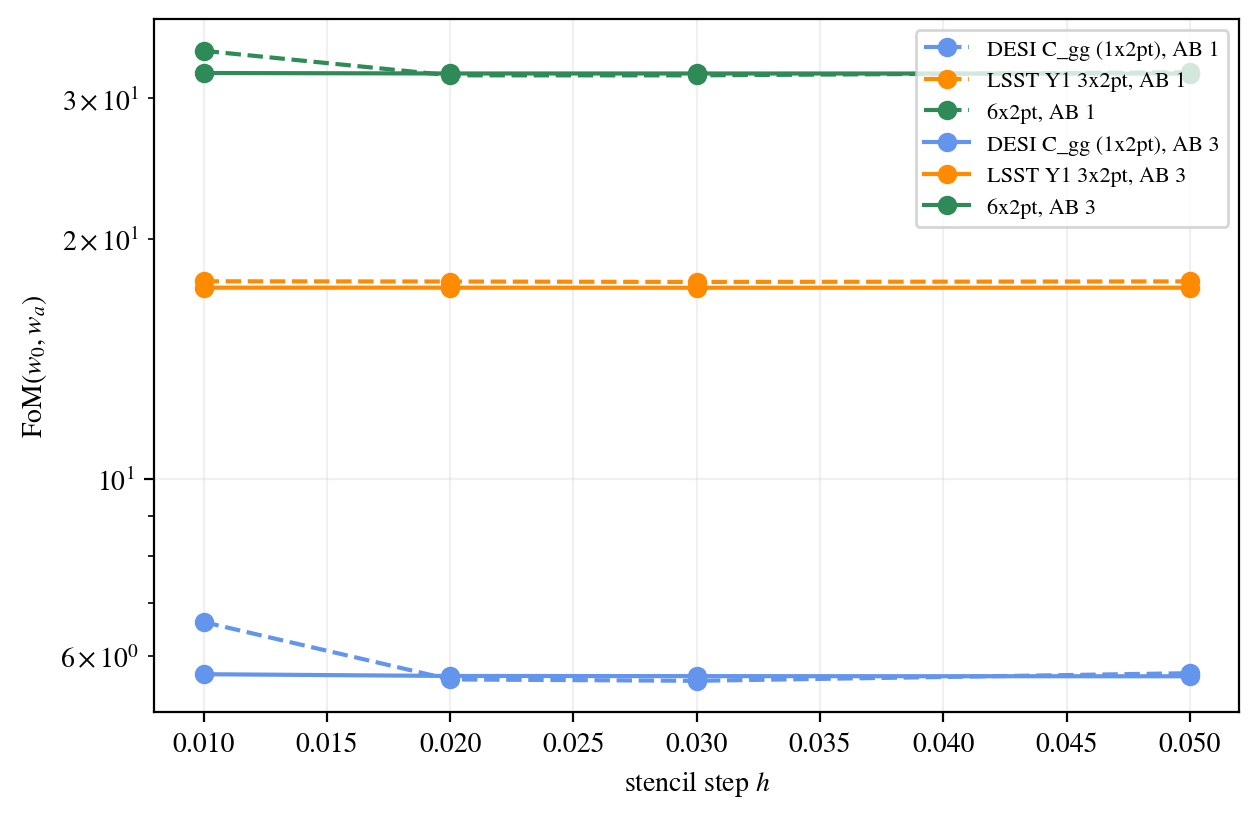

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
styles = dict(zip(ACCURACY_BOOSTS, ['--', '-', ':', '-.']))
colors = dict(zip(probes(H_MAIN), ['cornflowerblue', 'darkorange', 'seagreen']))
for boost in ACCURACY_BOOSTS:
    for label in probes(H_MAIN):
        fom = [stability.loc[(label, boost, h), 'FoM(w0, wa)'] for h in H_SCAN]
        ax.plot(H_SCAN, fom, marker='o', ls=styles[boost], color=colors[label],
                label=f'{label}, AB {boost:g}')
ax.set_xlabel(r'stencil step $h$')
ax.set_ylabel(r'FoM$(w_0, w_a)$')
ax.set_yscale('log')
ax.legend(fontsize=8)
plt.show()

## 6. Forecast contours

`cosmo_block` marginalizes the nuisances out of a Fisher matrix: the cosmology block of
$F^{-1}$ is the marginalized covariance, and its inverse is the Fisher matrix of the
seven cosmological parameters alone. `cnu.plot_Fisher` draws Gaussian samples of each
and hands them to getdist.

Removed no burn in
Removed no burn in
Removed no burn in


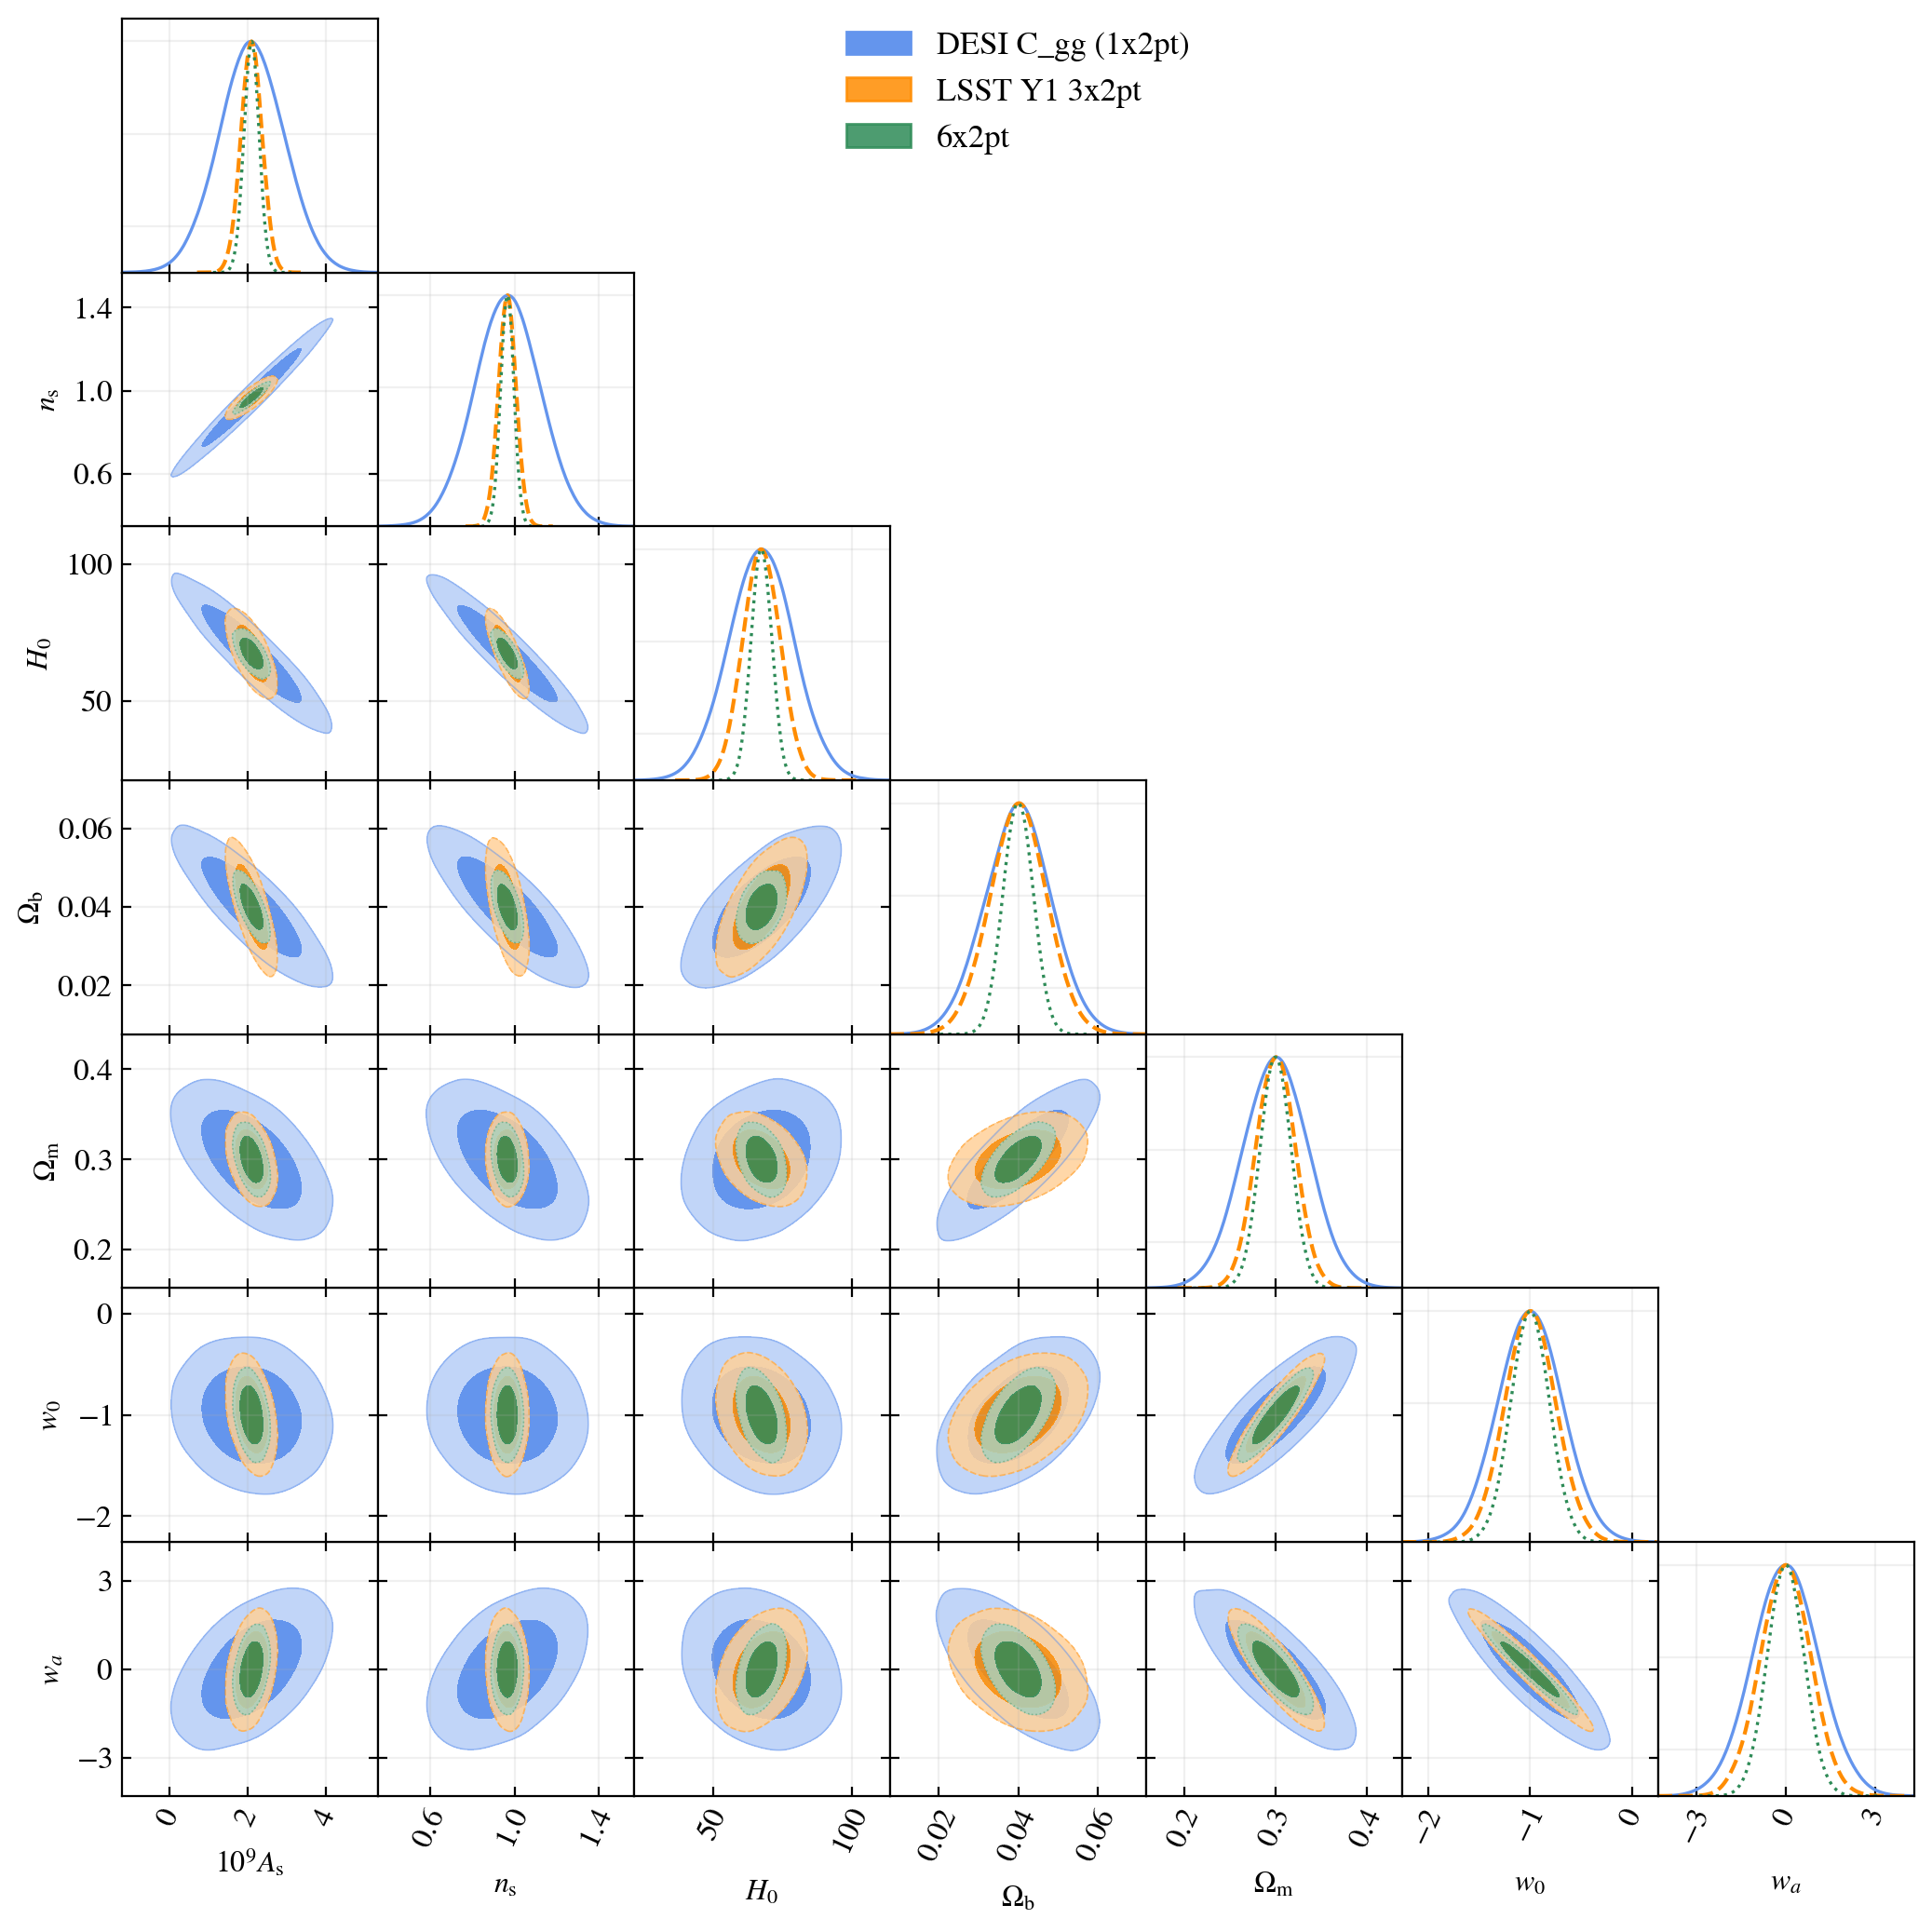

In [8]:
def cosmo_block(F, names):
    '''The Fisher matrix of COSMO with every other parameter marginalized.'''
    C = np.linalg.inv(0.5*(F + F.T))
    idx = [names.index(p) for p in COSMO]
    return np.linalg.inv(C[np.ix_(idx, idx)])


forecasts = probes(H_MAIN)
g = cnu.plot_Fisher(F=[cosmo_block(F, names) for F, names in forecasts.values()],
                    mu=desi['fiducial'][:len(COSMO)], names=COSMO,
                    labels=COSMO_LABELS, filled=True,
                    chain_names=list(forecasts))

## 7. Fisher biases: FKEM against SVD, Limber against non-Limber

Fit the reference model to data generated by an alternative model. To linear order in
$\delta = m_\mathrm{alt} - m_\mathrm{ref}$, the best fit moves by

$$\delta p = F^{-1} B, \qquad B = D^T C^{-1} \delta$$

(Huterer et al. 2006; Amara & Refregier 2008), with $D$ the derivatives of the reference
model. The nuisance parameters are part of $F$: the biases and velocity dispersions
absorb what they can of $\delta$, and the shift left in each cosmological parameter is
the marginalized one. The tables give $\delta p/\sigma$, the shift in units of the
marginalized error. The linear order holds while the shifts stay well below one
$\sigma$; a larger value says the alternative would be detected, and its size is only
indicative.

In the 6x2pt the numerators of the two blocks add, as their information does: an
alternative applied to DESI alone shifts the joint fit through the DESI block only.

In [9]:
def bias_in_sigma(F, names, shifts):
    '''delta_p/sigma of COSMO for the summed numerators of `shifts`.'''
    shift = fm.fisher_bias(F, names, *shifts)
    sigma = fm.marginalized_sigma(F, names, COSMO)
    return {p: shift[p]/sigma[p] for p in COSMO}


def bias_tables(h):
    '''{probe: DataFrame of delta_p/sigma and delta chi2} at step h.'''
    F6, names6 = six_by_two(h)
    cases = {
        'DESI C_gg (1x2pt)': (desi['F'][h], desi['names'],
                              {label: [('desi', label)] for label in DESI_ALTERNATIVES}),
        'LSST Y1 3x2pt': (lsst['F'][h], lsst['names'],
                          {label: [('lsst', label)] for label in LSST_ALTERNATIVES}),
        '6x2pt': (F6, names6, {
            'DESI FKEM, cap 550': [('desi', 'FKEM, cap 550')],
            'DESI Limber': [('desi', 'Limber')],
            'LSST SVD engine': [('lsst', 'SVD engine')],
            'Limber in both': [('desi', 'Limber'), ('lsst', 'Limber')]}),
    }
    tables = {}
    for probe, (F, names, alternatives) in cases.items():
        rows = {}
        for label, parts in alternatives.items():
            shifts = [(results[block]['B'][h][alt], results[block]['names'])
                      for block, alt in parts]
            rows[label] = {**bias_in_sigma(F, names, shifts),
                           'delta chi2': sum(results[block]['dchi2'][alt]
                                             for block, alt in parts)}
        tables[probe] = pd.DataFrame(rows).T
    return tables


biases = bias_tables(H_MAIN)
for probe, frame in biases.items():
    print(f'\n{probe}: delta_p / sigma at h = {H_MAIN}')
    display(frame)


DESI C_gg (1x2pt): delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
"FKEM, cap 550",-0.004455,-0.002627,0.005789,0.003009,-0.002474,0.005027,-0.004091,0.1148
Limber,3.366,5.614,-4.928,-4.919,-3.474,-1.116,2.838,331.8



LSST Y1 3x2pt: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
SVD engine,-0.0001273,0.0009722,-0.00242,-0.001006,0.00235,0.001926,-0.00233,0.0001386
Limber,-0.4048,0.2673,-0.2471,-0.2042,0.294,0.1167,-0.3129,11.18



6x2pt: delta_p / sigma at h = 0.02


,As_1e9,ns,H0,omegab,omegam,w0,wa,delta chi2
"DESI FKEM, cap 550",-0.006262,-0.01162,0.01308,0.005894,-0.001569,0.004918,-0.002172,0.1148
DESI Limber,-1.384,1.034,-1.692,-0.5644,1.356,1.193,-2.137,331.8
LSST SVD engine,-0.0008323,-0.0004413,-0.0008162,0.0003891,0.001485,0.001334,-0.001462,0.0001386
Limber in both,-1.415,1.081,-1.683,-0.678,1.289,1.084,-2.058,343


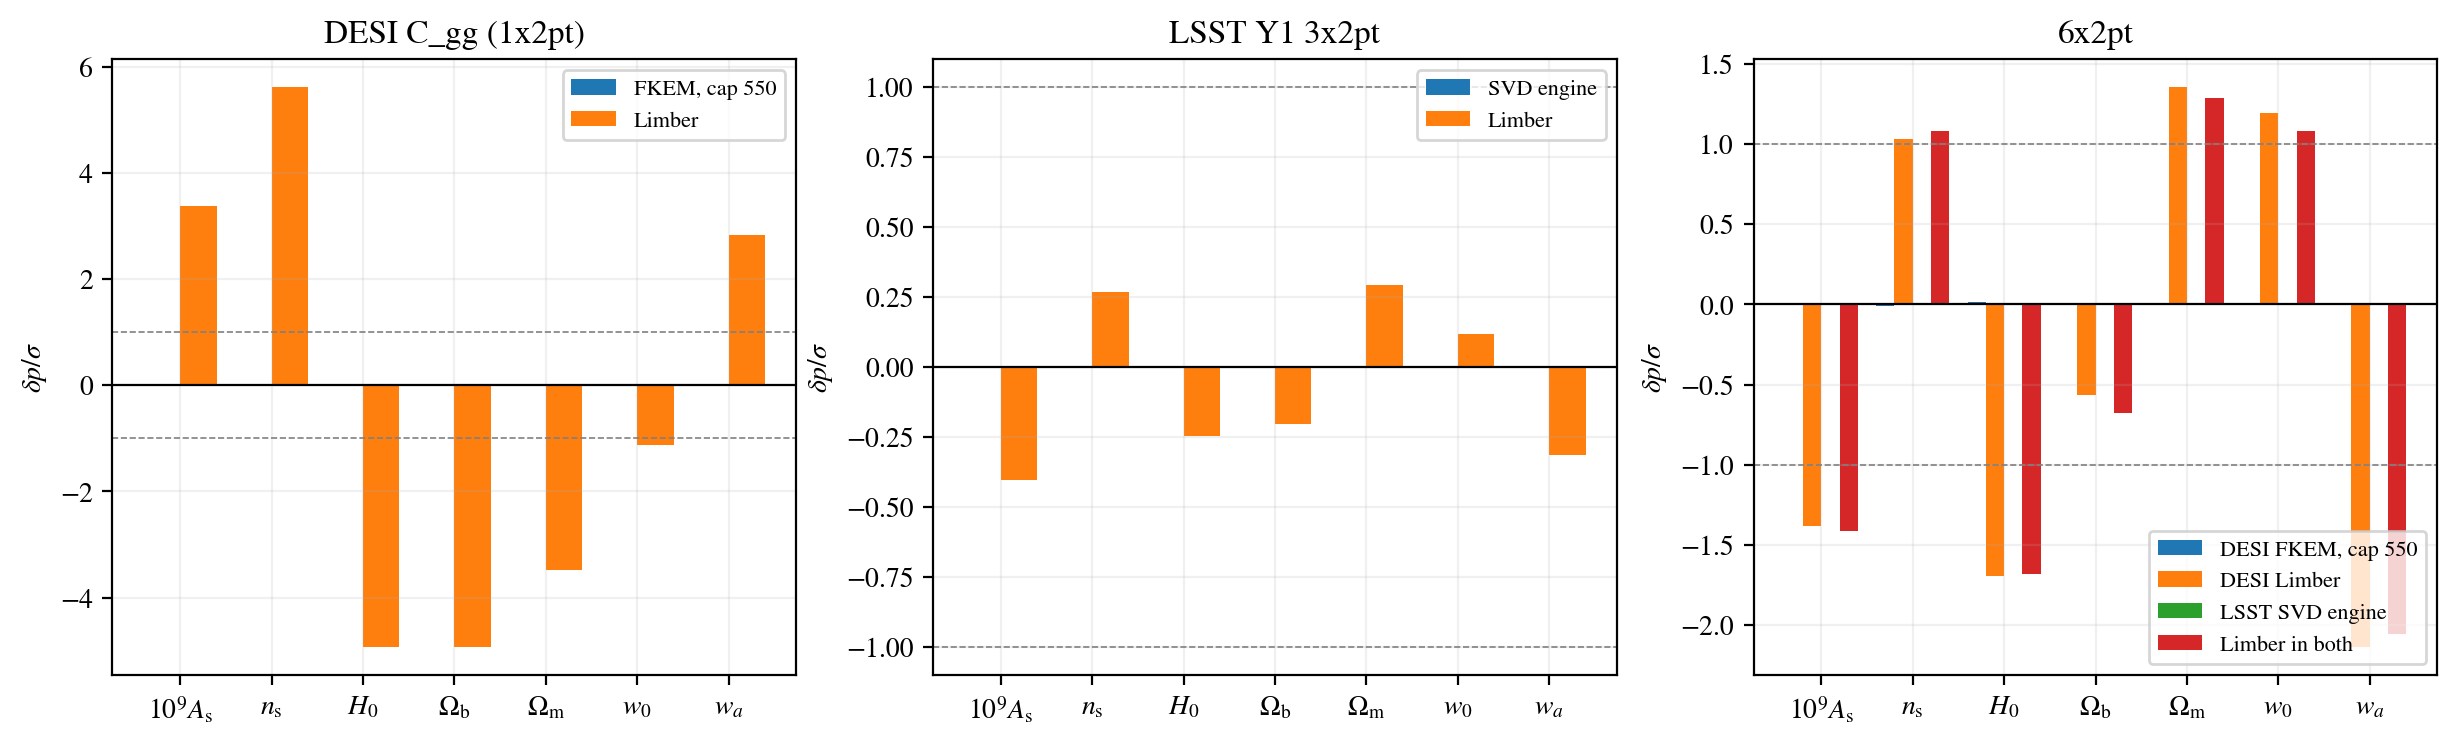

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
x = np.arange(len(COSMO))
for ax, (probe, frame) in zip(axes, biases.items()):
    width = 0.8/len(frame)
    for k, (label, row) in enumerate(frame.iterrows()):
        ax.bar(x + (k - (len(frame) - 1)/2)*width, [row[p] for p in COSMO],
               width=width, label=label)
    ax.axhline(0.0, color='black', lw=0.8)
    for level in (-1.0, 1.0):
        ax.axhline(level, color='gray', lw=0.6, ls='--')
    ax.set_xticks(x)
    ax.set_xticklabels(['$%s$' % s for s in COSMO_LABELS])
    ax.set_title(probe)
    ax.set_ylabel(r'$\delta p/\sigma$')
    ax.legend(fontsize=8)
plt.show()

### Fisher-bias stability against $h$

The shifts depend on the derivatives too, so they carry the same step dependence as
the errors. The table repeats every shift at each step of `H_SCAN`.

In [11]:
rows = {}
for h in H_SCAN:
    for probe, frame in bias_tables(h).items():
        for label, row in frame.iterrows():
            rows[(probe, label, h)] = row
pd.DataFrame(rows).T.sort_index()

As_1e9         ns         H0  \
6x2pt             DESI FKEM, cap 550 0.01  -0.006312   -0.01163    0.01303   
                                     0.02  -0.006262   -0.01162    0.01308   
                                     0.03  -0.006286   -0.01162    0.01305   
                                     0.05  -0.006251   -0.01163    0.01314   
                  DESI Limber        0.01     -1.377      1.036     -1.685   
                                     0.02     -1.384      1.034     -1.692   
                                     0.03     -1.386      1.035     -1.695   
                                     0.05     -1.384      1.036     -1.694   
                  LSST SVD engine    0.01 -0.0008337 -0.0004411 -0.0008186   
                                     0.02 -0.0008323 -0.0004413 -0.0008162   
                                     0.03 -0.0008324  -0.000441 -0.0008168   
                                     0.05  -0.000832 -0.0004405 -0.0008172   
                  Limber in both     0.01     -1.409      1.083     -1.677   
                                     0.02     -1.415      1.081     -1.683   
                                     0.03     -1.417      1.082     -1.686   
                                     0.05     -1.415      1.083     -1.685   
DESI C_gg (1x2pt) FKEM, cap 550      0.01  -0.004613  -0.002774   0.005889   
                                     0.02  -0.004455  -0.002627   0.005789   
                                     0.03  -0.004531    -0.0027    0.00584   
                                     0.05  -0.004538   -0.00272   0.005923   
                  Limber             0.01      3.361      5.613     -4.925   
                                     0.02      3.366      5.614     -4.928   
                                     0.03      3.368      5.614     -4.932   
                                     0.05      3.365      5.612     -4.929   
LSST Y1 3x2pt     Limber             0.01    -0.4056     0.2676    -0.2479   
                                     0.02    -0.4048     0.2673    -0.2471   
                                     0.03    -0.4051     0.2673    -0.2473   
                                     0.05    -0.4049     0.2674     -0.247   
                  SVD engine         0.01 -0.0001294  0.0009737  -0.002423   
                                     0.02 -0.0001273  0.0009722   -0.00242   
                                     0.03 -0.0001276  0.0009726   -0.00242   
                                     0.05 -0.0001267  0.0009733  -0.002421   

                                             omegab    omegam       w0  \
6x2pt             DESI FKEM, cap 550 0.01  0.005957 -0.001471 0.005044   
                                     0.02  0.005894 -0.001569 0.004918   
                                     0.03  0.005927 -0.001516 0.004986   
                                     0.05  0.005857 -0.001652 0.004824   
                  DESI Limber        0.01   -0.5754     1.341    1.176   
                                     0.02   -0.5644     1.356    1.193   
                                     0.03   -0.5613     1.362    1.199   
                                     0.05   -0.5641     1.358    1.196   
                  LSST SVD engine    0.01 0.0003904   0.00149 0.001339   
                                     0.02 0.0003891  0.001485 0.001334   
                                     0.03 0.0003896  0.001485 0.001334   
                                     0.05 0.0003891  0.001485 0.001334   
                  Limber in both     0.01   -0.6876     1.276     1.07   
                                     0.02    -0.678     1.289    1.084   
                                     0.03   -0.6746     1.294    1.091   
                                     0.05   -0.6777      1.29    1.087   
DESI C_gg (1x2pt) FKEM, cap 550      0.01  0.003186 -0.002302 0.005217   
                                     0.02  0.003009 -0.002474 0.005027   
                                     0.03  0.003095 -0.002384 0.0

## 8. The amplitude cut against the Fisher forecast

The galaxy power of a lens bin is proportional to $A_s b_i^2$. The flat priors let
$10^9 A_s$ range over $[0.5, 5]$ and every bias amplitude over $[0.8, 4]$, so without
a cut the amplitude ratio $A_s b_i^2/(A_s b_i^2)_\mathrm{fid}$ reaches about 50 for
the ELG groups, whose fiducial bias is 0.84. There a fixed relative numerical error
of the data vector costs many units of $\chi^2$ against the fiducial covariance (the
cost grows as the ratio squared): the N-random-models check of the
[data-vector tests](tests/data_vector/README.md#nmodels_check) fails on every layout
through that corner of the box.

Cutting the boxes at a ratio `AMPLITUDE_CUT` removes that corner, and it can only move
an inference if the data allow points near the cut. This section draws, for every DESI
layout of the project, the cut against that layout's own DESI $C_{gg}$ Fisher
forecast. The triangle shades the excluded region gray and draws the Fisher $1\sigma$
and $2\sigma$ contours (68.3% and 95.4% of a two-dimensional Gaussian) about the
fiducial, every other parameter marginalized:

- an $A_s$ – $b_i$ panel shades bin $i$'s own cut;
- a $b_i$ – $b_j$ panel shades the region either bin excludes at the fiducial $A_s$;
- a diagonal panel shades the part of the box excluded with the other parameters at
  the fiducial, and draws each forecast's marginal Gaussian.

A cut far outside the $2\sigma$ contours removes only prior volume the data already
exclude. The DESI $2\sigma$ contours reach a ratio of 2.11 on the $\Delta z = 0.2$
bins and 1.54 on $\Delta z = 0.05$, so the default cut of 8 keeps a wide margin while
bounding the amplitude, and with it the numerical error, of every bin. The value 8 is
the cut shared by all cosmolike projects in this group, and every example yaml carries
it as the cobaya prior `amplitude_cut`. Set `AMPLITUDE_CUT` and rerun the cells to
test another cut.

The $\Delta z = 0.2$ matrices come from the cache of section 3. The next cell
computes one DESI $C_{gg}$ Fisher matrix per remaining layout, or reads it from
`chains/EXAMPLE_EVALUATE{n}_FISHER_AB1.pkl`: the DR3 and $\Delta z = 0.02$ matrices
are not computed yet, and the first run builds each of them in about 40-50 minutes.

In [ ]:
# The DESI layouts of the project and their DESI C_gg Fisher matrices at the
# step H_MAIN. Delta z = 0.2 is the DESI probe of section 3 (at ACCURACY_BOOST);
# each other layout varies COSMO and its own DESI_ nuisances on its example
# yaml, with no alternative models.
from cobaya.yaml import yaml_load_file

# the largest allowed amplitude ratio (As/As_fid)(b_i/b_i,fid)^2: the cut of
# the example yamls' prior blocks
AMPLITUDE_CUT = 8.0
# the six bias groups of every layout, in the order of each layout's
# 'bias_leaders' (the n of the DESI_B1_<n> that carries the group)
BIAS_GROUP_LABELS = [
    r'b_\mathrm{BGS}',
    r'b_\mathrm{LRG1}',
    r'b_\mathrm{LRG2}',
    r'b_\mathrm{LRG3}',
    r'b_\mathrm{ELG1}',
    r'b_\mathrm{ELG2}',
]
# one cache per computed layout, n = the example yaml's number
LAYOUT_CACHE = (ROOTDIR + '/projects/lssty1xdesi/chains/'
                'EXAMPLE_EVALUATE{:d}_FISHER_AB1.pkl')
LAYOUTS = {
    'DR3': {
        'title': r'DESI DR3: 76 comoving bins',
        'yaml': PROJECT + 'EXAMPLE_EVALUATE1.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi.yaml',
        'bias_leaders': [1, 19, 30, 39, 50, 62],
        'cache': LAYOUT_CACHE.format(1),
    },
    'Delta z = 0.02': {
        'title': r'DESI DR1, $\Delta z = 0.02$: 90 bins',
        'yaml': PROJECT + 'EXAMPLE_EVALUATE2.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p02.yaml',
        'bias_leaders': [1, 16, 26, 36, 51, 66],
        'cache': LAYOUT_CACHE.format(2),
    },
    'Delta z = 0.05': {
        'title': r'DESI DR1, $\Delta z = 0.05$: 36 bins',
        'yaml': PROJECT + 'EXAMPLE_EVALUATE3.yaml',
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p05.yaml',
        'bias_leaders': [1, 7, 11, 15, 21, 27],
        'cache': LAYOUT_CACHE.format(3),
    },
    # the DESI probe of section 3, cached with the LSST probe in CACHE
    'Delta z = 0.2': {
        'title': r'DESI DR1, $\Delta z = 0.2$: 10 bins',
        'yaml': DESI_YAML,
        'bias_params': PROJECT + 'likelihood/params_desi_dr1_dz0p20.yaml',
        'bias_leaders': [1, 3, 4, 5, 7, 9],
        'cache': None,
    },
}
# Likelihood overrides of the three layouts computed here, at the overall
# accuracy LAYOUT_ACCURACY_BOOST = 1 (the yamls' own reference settings). A
# derivative on thin bins needs a combined chi-grid factor
# 2^ceil(log2(accuracyboost x nonlimber_accuracyboost)) of at least 64:
# DR3 and Delta z = 0.02 ship 2 x 32; Delta z = 0.05 ships 2 x 16 and is
# raised to 2 x 32.
LAYOUT_FISHER_OVERRIDES = {
    'DR3': {},
    'Delta z = 0.02': {},
    'Delta z = 0.05': {'nonlimber_accuracyboost': 32.0},
}
LAYOUT_ACCURACY_BOOST = 1.0


def layout_settings(key):
    '''The settings of one computed layout's DESI Fisher matrix.

    Arguments:
      key = a key of LAYOUT_FISHER_OVERRIDES.

    Returns:
      dict: the example yaml, the likelihood overrides, the overall
      accuracy boost, the inverse-covariance factor (the area) and the
      stencil steps. The cache stores it, so a cache computed with other
      settings is refused.
    '''
    return {
        'yaml': LAYOUTS[key]['yaml'],
        'likelihood_overrides': dict(LAYOUT_FISHER_OVERRIDES[key]),
        'accuracy_boost': LAYOUT_ACCURACY_BOOST,
        'invcov_scale': AREA_DEG2/DESI_COV_AREA_DEG2,
        'steps': [H_MAIN],
    }


def layout_fisher(key):
    '''One layout's DESI C_gg Fisher inputs, from its cache or computed.

    Computing builds the layout's reference model (run_probe with no
    alternatives) and writes the cache; RECOMPUTE = True rebuilds it.

    Arguments:
      key = a key of LAYOUT_FISHER_OVERRIDES.

    Returns:
      dict of run_probe at the single step H_MAIN, plus 'settings'
      (layout_settings).

    Raises:
      KeyError when the layout is not computed here; RuntimeError when the
      cache holds other settings.
    '''
    if key not in LAYOUT_FISHER_OVERRIDES:
        raise KeyError(f'{key!r} has no entry in LAYOUT_FISHER_OVERRIDES '
                       f'(computed layouts: {list(LAYOUT_FISHER_OVERRIDES)})')
    settings = layout_settings(key)
    cache = LAYOUTS[key]['cache']
    if RECOMPUTE or not os.path.exists(cache):
        print(f'{key}: DESI C_gg', flush=True)
        out = run_probe(settings['yaml'], ('DESI_',), {},
                        invcov_scale=settings['invcov_scale'],
                        accuracy_boost=settings['accuracy_boost'],
                        common_overrides=settings['likelihood_overrides'],
                        steps=settings['steps'])
        out['settings'] = settings
        with open(cache, 'wb') as f:
            pickle.dump(out, f)
        return out
    with open(cache, 'rb') as f:
        out = pickle.load(f)
    if out.get('settings') != settings:
        raise RuntimeError(f'{cache} holds the settings '
                           f'{out.get("settings")}, but this notebook asks '
                           f'for {settings}: set RECOMPUTE = True to '
                           'rebuild it')
    return out


def layout_probes(key):
    '''{label: (F, names)} of one layout's DESI C_gg and 6x2pt at H_MAIN.

    The 6x2pt adds the LSST Y1 3x2pt block of section 3 (at
    ACCURACY_BOOST), which does not depend on the DESI layout.
    '''
    res = {'desi': layout_desi[key], 'lsst': results['lsst']}
    desi_block = (res['desi']['F'][H_MAIN], res['desi']['names'])
    return {'DESI C_gg (1x2pt)': desi_block, '6x2pt': six_by_two(H_MAIN, res)}

In [ ]:
# {layout: DESI C_gg Fisher inputs}; Delta z = 0.2 is section 3's DESI probe
layout_desi = {}
for key in LAYOUT_FISHER_OVERRIDES:
    layout_desi[key] = layout_fisher(key)
layout_desi['Delta z = 0.2'] = desi

layout_table = {}
for key in layout_desi:
    for label, (F, names) in layout_probes(key).items():
        sigma, fom = cosmo_errors(F, names)
        row = {}
        for p in COSMO:
            row[f'sigma({p})'] = sigma[p]
        row['FoM(w0, wa)'] = fom
        layout_table[(key, label)] = row
display(pd.DataFrame(layout_table).T)

In [ ]:
def draw_amplitude_cut(key):
    '''Draw the amplitude cut against one layout's DESI C_gg forecast.

    The A_s box comes from the layout's example yaml, the bias boxes from
    its likelihood parameter file (a mapping with one entry per
    parameter); the contours are the DESI C_gg Fisher matrix at H_MAIN.

    Arguments:
      key = a key of LAYOUTS.

    Side effects: draws one figure, titled with the layout.
    '''
    layout = LAYOUTS[key]
    res = layout_desi[key]
    bias_labels = {}
    for leader, label in zip(layout['bias_leaders'], BIAS_GROUP_LABELS):
        bias_labels[f'DESI_B1_{leader}'] = label
    as_prior = yaml_load_file(layout['yaml'])['params']['As_1e9']['prior']
    bias_params = yaml_load_file(layout['bias_params'])
    boxes = {'As_1e9': (as_prior['min'], as_prior['max'])}
    for name in bias_labels:
        prior = bias_params[name]['prior']
        boxes[name] = (prior['min'], prior['max'])
    labels = dict(bias_labels)
    labels['As_1e9'] = COSMO_LABELS[0]
    fig, axes = cnu.plot_Fisher_amplitude_cut(
        F=[res['F'][H_MAIN]], names=[res['names']],
        fiducial=dict(zip(res['names'], res['fiducial'])),
        amplitude='As_1e9', biases=list(bias_labels), boxes=boxes,
        labels=labels, cut=AMPLITUDE_CUT,
        chain_names=['DESI C_gg (1x2pt)'], show=None)
    fig.suptitle(layout['title'], fontsize=15)
    plt.show()

### The cosmological prior walls

The examples' flat prior also has walls in the cosmology: $\Omega_m \in [0.2, 0.5]$,
$w_0 \le -1/3$ (an accelerating universe today), $-3 \le w_0 + w_a \le -0.01$ and
$H_0 \in [55, 91]$ km/s/Mpc. Beyond the $w_0 + w_a = -3$ wall (an early phantom
regime) and at low $\Omega_m$ the numerical error of the data vector grows - the
low-$\Omega_m$ corner is why every likelihood ships `kmax_boltzmann: 20`, as the
[data-vector tests](tests/data_vector/README.md#nmodels_check) record. For each
layout a second triangle draws the Fisher contours of DESI clustering alone and of
the 6x2pt combination against the $\Omega_m$, $w_0$ and $w_0 + w_a$ walls. The cells
read the walls from each example yaml, so they redraw whatever prior the yamls hold.

In [ ]:
def draw_prior_walls(key):
    '''Draw the cosmological prior walls against one layout's forecasts.

    The walls are the omegam and w0 (`w`) boxes and the w0 + wa (`w0pwa`)
    box of the layout's example yaml; the contours are its DESI C_gg and
    6x2pt Fisher matrices at H_MAIN (layout_probes).

    Arguments:
      key = a key of LAYOUTS.

    Side effects: draws one figure, titled with the layout.
    '''
    layout = LAYOUTS[key]
    res = layout_desi[key]
    example_params = yaml_load_file(layout['yaml'])['params']
    wall_boxes = {}
    for name, yaml_name in (('omegam', 'omegam'), ('w0', 'w')):
        prior = example_params[yaml_name]['prior']
        wall_boxes[name] = (prior['min'], prior['max'])
    w0pwa_prior = example_params['w0pwa']['prior']
    walls = [({'w0': 1.0, 'wa': 1.0}, w0pwa_prior['min'], w0pwa_prior['max'])]
    forecasts = layout_probes(key)
    wall_labels = ['DESI C_gg (1x2pt)', '6x2pt']
    matrices = []
    name_lists = []
    for label in wall_labels:
        matrices.append(forecasts[label][0])
        name_lists.append(forecasts[label][1])
    fig, axes = cnu.plot_Fisher_prior_walls(
        F=matrices, names=name_lists,
        fiducial=dict(zip(res['names'], res['fiducial'])),
        params=['omegam', 'w0', 'wa'],
        ranges={'omegam': (0.1, 0.6), 'w0': (-3.2, 0.2), 'wa': (-5.0, 5.0)},
        boxes=wall_boxes, walls=walls, labels=dict(zip(COSMO, COSMO_LABELS)),
        chain_names=wall_labels, show=None)
    fig.suptitle(layout['title'], fontsize=15)
    plt.show()

### DR3

76 comoving bins about 62 Mpc wide. The DESI $C_{gg}$ Fisher matrix of this layout
is not computed yet: the first run of the cells below builds it (about 40-50 minutes)
and caches it in `chains/EXAMPLE_EVALUATE1_FISHER_AB1.pkl`, and later runs read the
cache.

In [ ]:
draw_amplitude_cut('DR3')

In [ ]:
draw_prior_walls('DR3')

### $\Delta z = 0.02$

90 bins of width $\Delta z = 0.02$. The DESI $C_{gg}$ Fisher matrix of this layout
is not computed yet: the first run of the cells below builds it (about 40-50 minutes)
and caches it in `chains/EXAMPLE_EVALUATE2_FISHER_AB1.pkl`, and later runs read the
cache.

In [ ]:
draw_amplitude_cut('Delta z = 0.02')

In [ ]:
draw_prior_walls('Delta z = 0.02')

### $\Delta z = 0.05$

36 bins of width $\Delta z = 0.05$, computed with the $\chi$-grid override
`nonlimber_accuracyboost: 32` of `LAYOUT_FISHER_OVERRIDES` (a derivative needs a
denser grid than the 16 the likelihood ships). Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 1.54, far inside the
  cut at 8;
- no DESI or 6x2pt $2\sigma$ contour touches a prior wall: the DESI $2\sigma$ ranges
  are $\Omega_m$ 0.254-0.346, $w_0$ up to $-0.66$ and $w_0 + w_a$ from $-1.81$ to
  $-0.19$;
- DESI alone reaches $\sigma(\Omega_m) = 0.0186$, $\sigma(w_0) = 0.138$ and
  $\sigma(w_a) = 0.437$, with FoM$(w_0, w_a) = 32$; the 6x2pt combination reaches
  FoM $= 72.5$.

In [ ]:
draw_amplitude_cut('Delta z = 0.05')

In [ ]:
draw_prior_walls('Delta z = 0.05')

### $\Delta z = 0.2$

The ten wide bins of the main forecast; the matrices are those of section 3, at the
overall accuracy boost `ACCURACY_BOOST` = 3 that `fm.boost_accuracy` splits between
CAMB and cosmolike. Measured at the step $h = 0.02$:

- the largest amplitude ratio on the DESI $2\sigma$ contours is 2.11, still far
  inside the cut at 8;
- the DESI-alone $2\sigma$ contours cross the $w_0 = -1/3$ wall and both $w_0 + w_a$
  walls ($w_0 + w_a$ spans $-3.11$ to $1.11$): on these wide bins DESI clustering
  alone is partly prior-bounded in the $w_0$ - $w_a$ plane;
- the 6x2pt $2\sigma$ contour crosses only the $w_0 + w_a = -0.01$ wall, reaching
  0.10, and $\Omega_m$ stays inside $[0.2, 0.5]$ for both probes;
- FoM$(w_0, w_a)$: DESI alone 5.7, the 6x2pt combination 32.2.

In [ ]:
draw_amplitude_cut('Delta z = 0.2')

In [ ]:
draw_prior_walls('Delta z = 0.2')

## 9. Limits of this forecast

- **Gaussian covariance only.** Super-sample covariance and the connected trispectrum
  are left out; the shear and galaxy-galaxy lensing signal inside the Gaussian term
  carries NLA with the power law evaluated at each source bin's mean redshift.
- **Independent probes.** The 6x2pt sum ignores the LSST×DESI cross spectra and the
  covariance between the two data vectors, although the footprints overlap.
- **Linear Fisher biases.** Shifts of order one $\sigma$ or more are outside the linear
  regime; a chain fitted to the alternative vector measures them properly.
- **The numerical floor.** With the halofit patch and the DESI $\chi$-grid boost, the
  vectors are smooth to about $10^{-3}\sqrt{\chi^2}$ per evaluation; section 5 shows
  what is left of the step and accuracy dependence.